In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

In [2]:
# 1. Load dataset
df = pd.read_csv("sales_data_sample.csv", encoding="latin1", on_bad_lines="skip")
print("Dataset Shape:", df.shape)
print(df.head())

Dataset Shape: (2823, 25)
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue

In [3]:
# 2. Select numerical features
X = df.select_dtypes(include=["int64", "float64"])
X = X.fillna(X.median())

In [4]:
# 3. Standardize data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


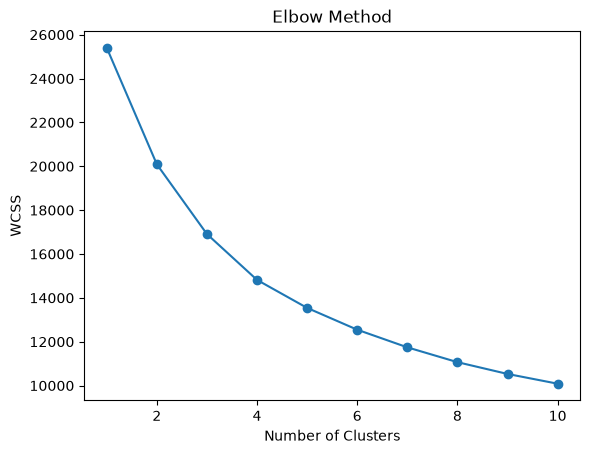

In [5]:
# 4. Elbow Method
wcss = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    wcss.append(km.inertia_)

plt.plot(range(1, 11), wcss, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.show()

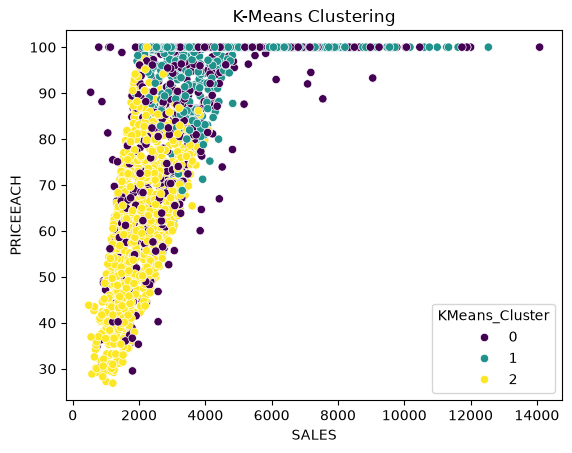

K-Means Cluster Counts:
KMeans_Cluster
1    1183
2     906
0     734
Name: count, dtype: int64


In [6]:
# 5. K-Means Clustering
km = KMeans(n_clusters=3, random_state=42, n_init=10)
df["KMeans_Cluster"] = km.fit_predict(X_scaled)

sns.scatterplot(x="SALES", y="PRICEEACH", hue="KMeans_Cluster",
                data=df, palette="viridis")
plt.title("K-Means Clustering")
plt.show()

print("K-Means Cluster Counts:")
print(df["KMeans_Cluster"].value_counts())


Performing Hierarchical Clustering...


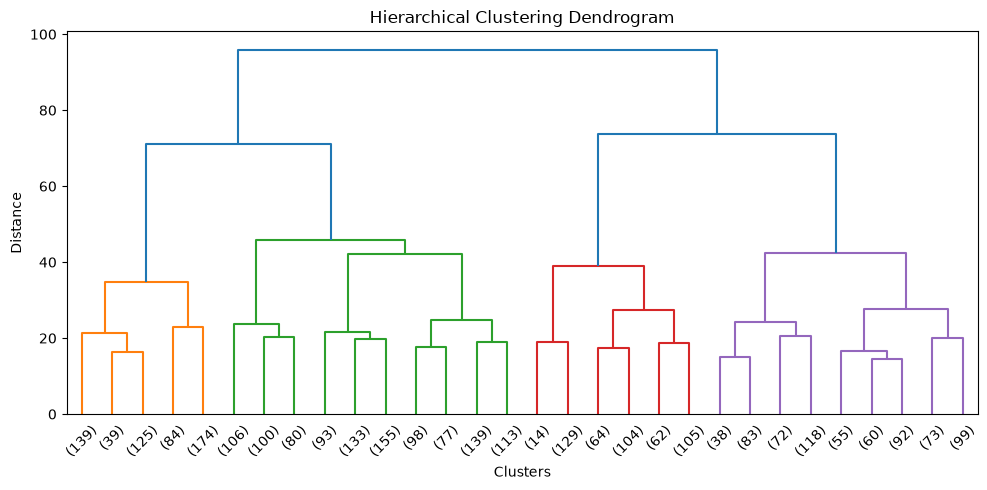

In [22]:
print("\nPerforming Hierarchical Clustering...")

# Create linkage matrix
Z = linkage(X_scaled, method="ward")

# Plot dendrogram (show only first 100 samples for readability)
plt.figure(figsize=(10, 5))
dendrogram(Z, truncate_mode="lastp", p=30)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Clusters")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()

# Create 3 clusters
clusters_hier = fcluster(Z, t=3, criterion="maxclust")
df["Hierarchical_Cluster"] = clusters_hier

In [21]:

# Display output
print("\nHierarchical Clustering Results:")
print(df[["Hierarchical_Cluster"]].head(10))

print("\nHierarchical Cluster Counts:")
print(df["Hierarchical_Cluster"].value_counts().sort_index())


Hierarchical Clustering Results:
   Hierarchical_Cluster
0                     3
1                     3
2                     1
3                     1
4                     1
5                     1
6                     1
7                     1
8                     1
9                     3

Hierarchical Cluster Counts:
Hierarchical_Cluster
1    1655
2     478
3     690
Name: count, dtype: int64
